# Naïve Bayes (NB): Spambase
**Goal:** Classify emails as spam (1) or not spam (0) from 57 numerical features. Source: uploaded UCI Spambase.

**Method:** Gaussian Naïve Bayes; because features are continuous frequencies and capital-letter statistics. The train/test split is stratified. We assess accuracy, precision, recall and a confusion matrix.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from pathlib import Path
DATA = Path('data')
if not DATA.exists():
    DATA = Path('KNN_NB_assignment/data')

df=pd.read_csv(DATA/'spambase.data',header=None)
X=df.iloc[:,:-1]
y=df.iloc[:,-1].astype(int)
print('Rows, features:',X.shape)
print('Class counts:',y.value_counts().to_dict())
display(df.head())

Rows, features: (4601, 57)
Class counts: {0: 2788, 1: 1813}


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,0.00,0.64,0.00,0.00,0.00,0.32,0.00,1.29,1.93,0.00,0.96,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,0.21,0.79,0.65,0.21,0.14,0.14,0.07,0.28,3.47,0.00,1.59,0.0,0.43,0.43,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.07,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,0.38,0.45,0.12,0.00,1.75,0.06,0.06,1.03,1.36,0.32,0.51,0.0,1.16,0.06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.06,0.0,0.0,0.12,0.0,0.06,0.06,0.0,0.0,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,0.31,0.31,0.31,0.00,0.00,0.31,0.00,0.00,3.18,0.00,0.31,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,0.31,0.31,0.31,0.00,0.00,0.31,0.00,0.00,3.18,0.00,0.31,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


Test accuracy: 0.831
              precision    recall  f1-score   support

    Not spam       0.96      0.75      0.84       697
        Spam       0.71      0.95      0.82       454

    accuracy                           0.83      1151
   macro avg       0.84      0.85      0.83      1151
weighted avg       0.86      0.83      0.83      1151



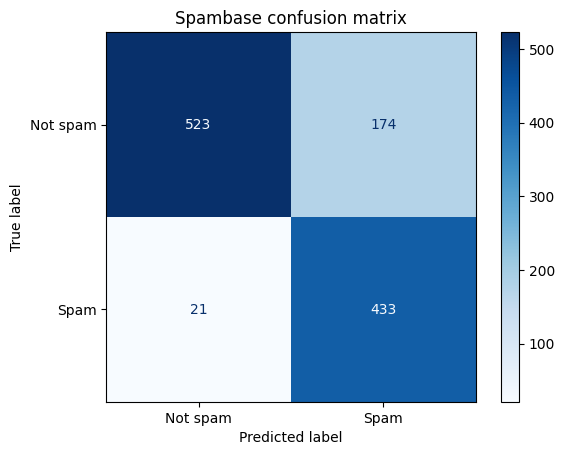

In [2]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42,stratify=y)
model=GaussianNB()
model.fit(X_train,y_train)
pred=model.predict(X_test)
acc=accuracy_score(y_test,pred)
print(f'Test accuracy: {acc:.3f}')
print(classification_report(y_test,pred,target_names=['Not spam','Spam'],zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=['Not spam','Spam'],cmap='Blues')
plt.title('Spambase confusion matrix');plt.show()

## Explain to a general audience (English)
The model looks at how often certain words and characters appear in an email, as well as patterns in capital letters. It uses probability to decide whether the message resembles spam or legitimate mail. **Run the notebook and insert the actual result:** “It correctly classified ___% of the held-out emails.” A false positive incorrectly marks a legitimate message as spam, whereas a false negative allows spam to reach the inbox.

**Limitations:** The dataset reflects historic email patterns; performance on modern phishing emails may differ. The method also assumes features are conditionally independent, which is often only an approximation.